# Highlight cases: where the CAV gate changes motifbreakR's prediction, Malinois and Kircher

The P gate (NT-v2 500M, layer 24): every motifbreakR call's alleleDiff × the percentile of its occurrence's P(bound | ref)
among the calls of the same TF; per variant the call with the largest |gated score|. Here: concrete variants, where
they are, which TF, and how often the gate helps vs hurts, so the examples are not cherry-picked.

**Case types** (fixed in advance; Malinois in HepG2 and K562, active elements, TFs with CAV AUC ≥ 0.75; Kircher in the 4
HepG2/K562 regions, clear = strongest 15% |log2FC| of the region):

| type | definition | the opposite (counted too) |
|---|---|---|
| **sign fixed** | clear effect; motifbreakR's sign is wrong, the gate's sign is right (the gate switched to another TF's call) | sign broken: motifbreakR right, gate wrong |
| **false alarm removed** | strong motifbreakR call (\|alleleDiff\| ≥ 0.9) on a site the CAV calls unbound, so the gate keeps ≤ 25% of it; no effect measured (\|Δ\| < 1 SE) | real effect suppressed: same, but a clear effect |
| **real effect kept** | clear effect, motifbreakR's sign right, the site called bound (gate keeps ≥ 75%) | — |

Then: the top cases of each type with nearest protein-coding gene (Ensembl REST), a figure per Malinois case (the 200 bp
element, its motif occurrences coloured by P percentile, measured Δ vs both predictions), and mirrored region tracks
for the 4 Kircher regions (measured up, predictions down, as suggested at the 10-13 meeting). CPU only.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Shared

In [2]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, re, time
import numpy as np, pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

MAL = f"{WORK_DIR}/malinois"
POOL = f"{WORK_DIR}/fcav_pool"
OUT = f"{WORK_DIR}/highlight_cases"
os.makedirs(OUT, exist_ok=True)
LAYER, AUC_MIN, N_TOP = 24, 0.75, 8
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 40)
INK = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
AUC, KP = {}, {}
for f in os.listdir(f"{POOL}/fits/nt500m"):
    if f.endswith(".npz") and not f.endswith(".part.npz"):
        z = np.load(f"{POOL}/fits/nt500m/{f}", allow_pickle=False)
        li = [int(l) for l in z["layers"]].index(LAYER)
        AUC[f[:-4]] = float(np.asarray(z["auc"])[li])
        for r, h, p in zip(z["hit_region"].astype(int), z["hit_id"].astype(int), z["prob_hit"][:, li]):
            KP[r, h] = float(p)


def tf_pct(x, g):
    o = np.lexsort((x, g))
    gs = g[o]
    st = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    cnt = np.diff(np.r_[st, len(gs)])
    q = np.empty(len(x)); q[o] = (np.arange(len(gs)) - np.repeat(st, cnt) + 0.5) / np.repeat(cnt, cnt)
    return q


def pick_idx(v, grp, n):
    out = np.full(n, -1)
    if len(v):
        o = np.lexsort((-np.abs(v), grp))
        f = o[np.r_[True, grp[o][1:] != grp[o][:-1]]]
        out[grp[f]] = f
    return out


def calls_table(ad, tf_names, grp, p, n):
    # motifbreakR's call and the gate's call per variant: index, TF, alleleDiff, percentile, prediction
    tf = pd.factorize(tf_names)[0]
    q = tf_pct(p, tf)
    i_mb, i_g = pick_idx(ad, grp, n), pick_idx(ad * q, grp, n)
    ok = i_mb >= 0
    t = pd.DataFrame(index=np.arange(n))
    for nm, idx in (("mbR", i_mb), ("gate", i_g)):
        t[f"{nm} TF"] = np.where(ok, np.asarray(tf_names, dtype=object)[np.clip(idx, 0, None)], None)
        t[f"{nm} alleleDiff"] = np.where(ok, ad[np.clip(idx, 0, None)], 0.0)
        t[f"{nm} P pct"] = np.where(ok, q[np.clip(idx, 0, None)], np.nan)
    t["pred mbR"] = t["mbR alleleDiff"]
    t["pred gate"] = t["gate alleleDiff"] * t["gate P pct"]
    t["gate keeps"] = np.abs(t["pred gate"]) / np.abs(t["pred mbR"]).replace(0, np.nan)
    return t


def classify(t, y, clear, noeff):
    s_mb, s_g, s_y = np.sign(t["pred mbR"]), np.sign(t["pred gate"]), np.sign(y)
    strong = t["pred mbR"].abs() >= 0.9
    return {"sign fixed": clear & (s_mb != s_y) & (s_g == s_y),
            "sign broken": clear & (s_mb == s_y) & (s_g != s_y),
            "false alarm removed": strong & (t["gate keeps"] <= 0.25) & noeff,
            "real effect suppressed": strong & (t["gate keeps"] <= 0.25) & clear,
            "real effect kept": clear & (s_mb == s_y) & (t["gate keeps"] >= 0.75)}


_GENE = {}


def nearest_gene(chrom, pos):
    # nearest protein-coding gene TSS within 200 kb (Ensembl REST, GRCh38)
    key = (chrom, int(pos) // 1000)
    if key in _GENE:
        return _GENE[key]
    c = str(chrom).replace("chr", "")
    try:
        r = requests.get(f"https://rest.ensembl.org/overlap/region/human/{c}:{max(1, pos - 200000)}-{pos + 200000}",
                         params={"feature": "gene"}, headers={"Content-Type": "application/json"}, timeout=30)
        genes = [g for g in r.json() if g.get("biotype") == "protein_coding" and g.get("external_name")]
        best = min(genes, key=lambda g: abs((g["start"] if g["strand"] == 1 else g["end"]) - pos)) if genes else None
        out = (best["external_name"], int((best["start"] if best["strand"] == 1 else best["end"]) - pos)) if best else ("", np.nan)
    except Exception as e:
        out = (f"(lookup failed: {type(e).__name__})", np.nan)
    _GENE[key] = out
    time.sleep(0.1)
    return out

---
# Section 1 — Malinois

## 1.1 Calls, the two predictions, and how often each type happens

In [3]:
CELLS2 = ["HepG2", "K562"]
V = pd.read_csv(f"{MAL}/variants.csv.gz", index_col="vi", dtype={"chrom": str}, low_memory=False)
rd = lambda d: pd.concat([pd.read_csv(f"{d}/{f}") for f in os.listdir(d) if f.endswith(".csv") and not f.endswith(".part.csv")])
H = pd.read_csv(f"{MAL}/hits.csv")
H = H[~H["leak"]]
H["P"] = rd(f"{MAL}/p_nt500m").set_index("uid")["P"].reindex(H["uid"]).values
CM = pd.read_csv(f"{MAL}/calls.csv").merge(H.groupby(["vi", "motif"])["P"].max().reset_index(), on=["vi", "motif"])
CM = CM[CM["motif"].map(AUC) >= AUC_MIN].sort_values(["vi", "motif"]).reset_index(drop=True)
VI = np.unique(CM["vi"].values)
T = calls_table(CM["alleleDiff"].values, CM["motif"].values, np.searchsorted(VI, CM["vi"].values), CM["P"].values, len(VI))
T.index = VI
print(f"{len(CM):,} calls of {CM['motif'].nunique()} TFs (CAV AUC >= {AUC_MIN}) on {len(VI):,} variants; "
      f"the gate picks another TF's call for {np.mean(T['mbR TF'] != T['gate TF']):.1%} of them")
TYPES, rows = {}, []
for c in CELLS2:
    y, se = V.loc[VI, f"d_{c}"].values, V.loc[VI, f"se_{c}"].values
    act = V.loc[VI, f"act_{c}"].values >= 1
    z = np.abs(y) / se
    K = classify(T, y, act & (z >= 2), act & (z < 1))
    TYPES[c] = {k: v & act for k, v in K.items()}
    rows.append({"cell": c, "active variants": int(act.sum()), **{k: int(v.sum()) for k, v in TYPES[c].items()}})
print("\nnumber of variants of each type (the pairs to compare: fixed vs broken, removed vs suppressed)\n")
print(pd.DataFrame(rows).set_index("cell").to_string())

47,116 calls of 95 TFs (CAV AUC >= 0.75) on 35,708 variants; the gate picks another TF's call for 9.9% of them

number of variants of each type (the pairs to compare: fixed vs broken, removed vs suppressed)

       active variants  sign fixed  sign broken  false alarm removed  real effect suppressed  real effect kept
cell                                                                                                          
HepG2             8872          22            9                  287                     176               839
K562              8837          20           11                  281                     169               825


## 1.2 The top cases (by |Δ / SE|; false alarms by the strongest motifbreakR call), with the nearest gene

In [4]:
CASES = []
for c in CELLS2:
    y, se = V.loc[VI, f"d_{c}"].values, V.loc[VI, f"se_{c}"].values
    for typ in ("sign fixed", "false alarm removed", "real effect kept"):
        m = TYPES[c][typ].values if hasattr(TYPES[c][typ], "values") else TYPES[c][typ]
        idx = np.flatnonzero(m)
        key = -np.abs(T["pred mbR"].values[idx]) + np.abs(y[idx] / se[idx]) * 1e-3 if typ == "false alarm removed" else -np.abs(y[idx] / se[idx])
        for j in idx[np.argsort(key)][:N_TOP]:
            vi = VI[j]
            g, dist = nearest_gene(V.at[vi, "chrom38"], int(V.at[vi, "pos38"]))
            CASES.append({"cell": c, "type": typ, "vi": vi,
                          "variant (hg38)": f"{V.at[vi, 'chrom38']}:{int(V.at[vi, 'pos38']) + 1} {V.at[vi, 'ref']}>{V.at[vi, 'alt']}",
                          "source": V.at[vi, "data_project"], "nearest gene": g, "TSS distance": dist,
                          "measured Δ": y[j], "Δ/SE": y[j] / se[j],
                          "mbR TF": T.at[vi, "mbR TF"], "mbR pred": T.at[vi, "pred mbR"], "mbR P pct": T.at[vi, "mbR P pct"],
                          "gate TF": T.at[vi, "gate TF"], "gate pred": T.at[vi, "pred gate"], "gate P pct": T.at[vi, "gate P pct"]})
CA = pd.DataFrame(CASES)
CA.to_csv(f"{OUT}/malinois_cases.csv", index=False)
for (c, typ), g in CA.groupby(["cell", "type"], sort=False):
    print(f"\n=== {c}: {typ}\n")
    print(g.drop(columns=["cell", "type", "vi"]).to_string(index=False, float_format=lambda x: f"{x:+.2f}"))


=== HepG2: sign fixed

     variant (hg38) source                     nearest gene  TSS distance  measured Δ   Δ/SE mbR TF  mbR pred  mbR P pct gate TF  gate pred  gate P pct
  chr1:95619347 A>T   GTEX                                            NaN       -2.07 -12.67  DMTF1     +0.82      +0.29    ETV1      -0.37       +0.52
 chr9:133434495 A>C   GTEX                            REXO4     -16398.00       +0.96  +7.45 ZNF148     -0.72      +0.01     SP2      +0.28       +0.41
 chr2:112630322 G>C   GTEX                          SLC20A1     +15532.00       +0.56  +5.00  GABPA     -0.53      +0.56    Spi1      +0.41       +0.88
chr15:101494716 G>A   GTEX                            PCSK6     +30487.00       +0.65  +4.75    SP4     -0.79      +0.27  ZNF281      +0.36       +0.81
  chr8:22097243 A>G   GTEX     (lookup failed: ReadTimeout)           NaN       -0.72  -4.53 ZNF148     +0.83      +0.09  ZNF263      -0.70       +0.84
 chr17:30475341 T>C   GTEX (lookup failed: JSONDecodeError)     

## 1.3 One figure per case (first 3 of each type in HepG2): the element, its motif occurrences, and the numbers

Top: the 200 bp tested element; each motif occurrence that contains the variant is a box, coloured by its P(bound)
percentile within its TF (dark = bound), the variant is the red line. Bottom: measured Δ (± 1.96 SE), motifbreakR's
prediction and the gated prediction (both scaled to the measured Δ's size for display; only sign and relative size matter).

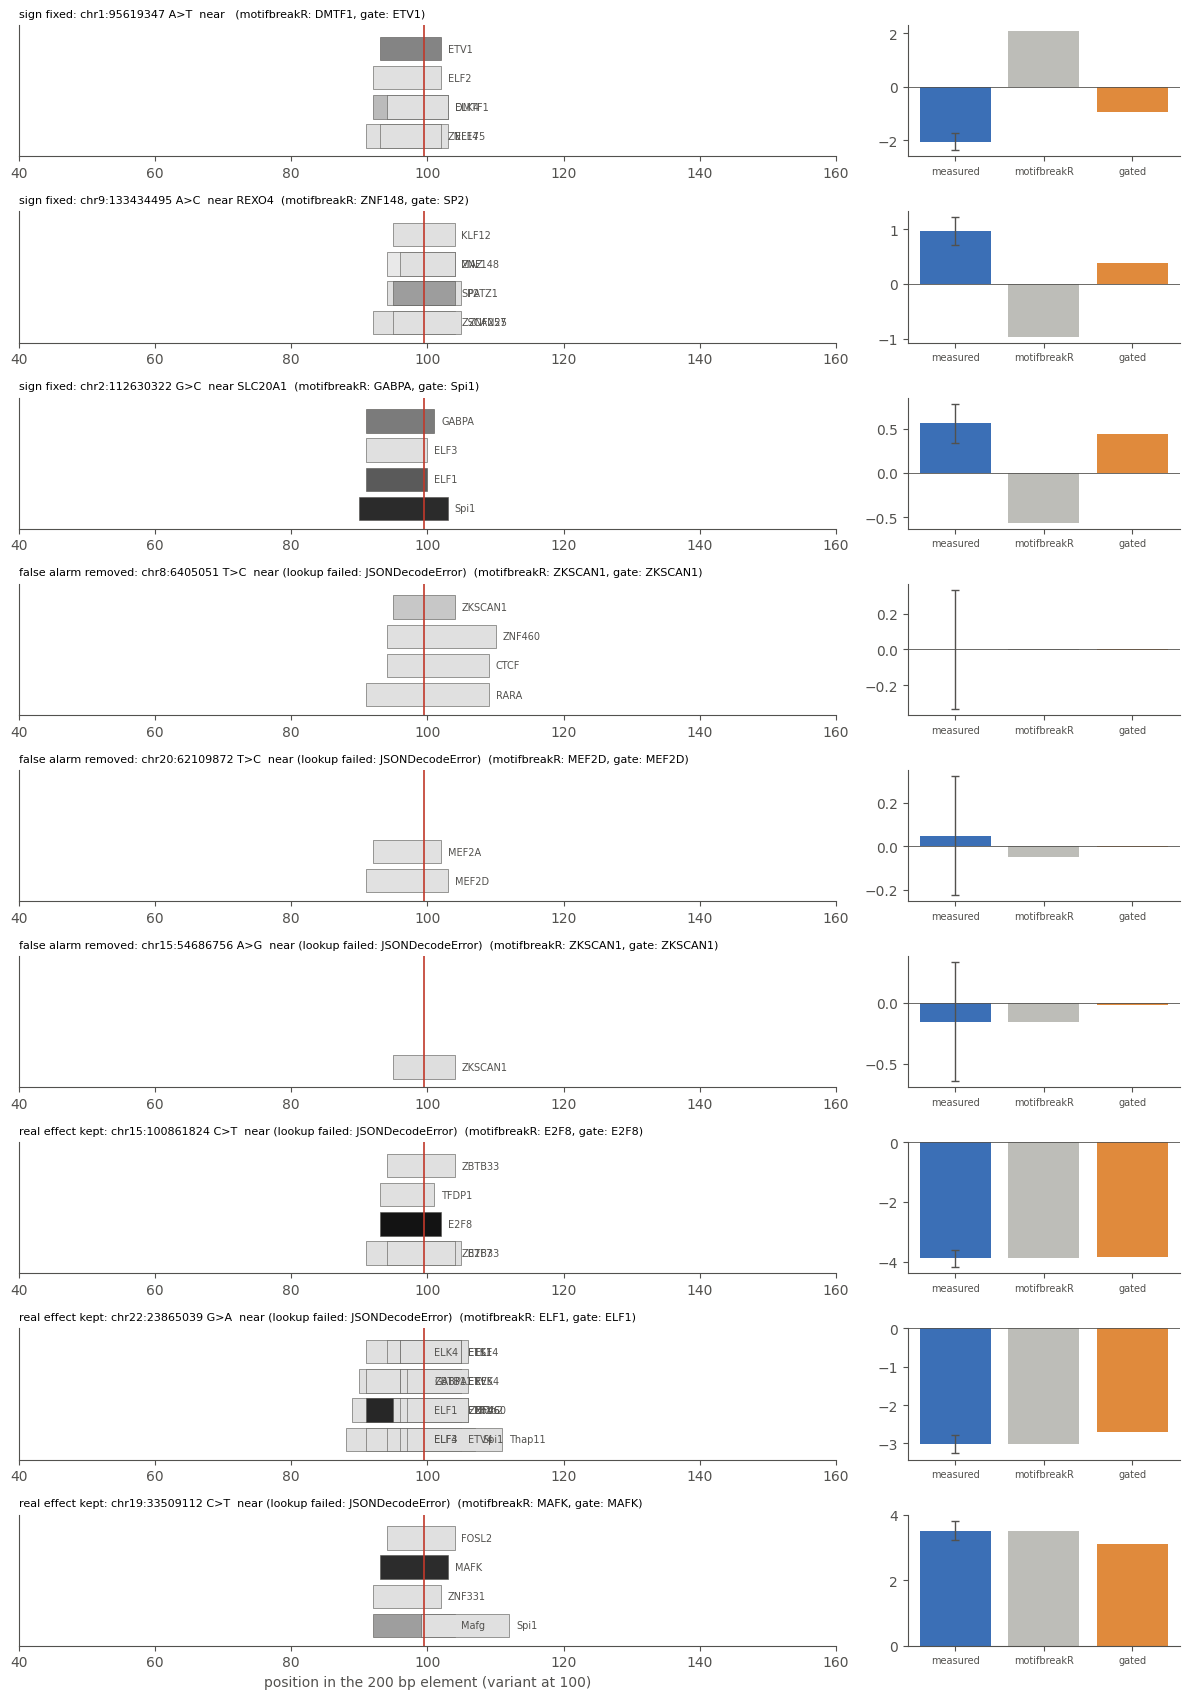

In [5]:
cmap = plt.get_cmap("Greys")
HV = H.set_index("vi")
CMI = CM.set_index(["vi", "motif"])
sub = CA[CA["cell"] == "HepG2"].groupby("type", sort=False).head(3)
assert len(sub), "no HepG2 cases to draw"
fig, axes = plt.subplots(len(sub), 2, figsize=(12, 1.9 * len(sub)), gridspec_kw={"width_ratios": [3, 1]}, squeeze=False)
for row, (_, cs) in zip(axes, sub.iterrows()):
    a, b = row
    vi = cs["vi"]
    hv = HV.loc[[vi]].drop_duplicates("uid")
    pct = {m: tf_pct(CM.loc[CM["motif"] == m, "P"].values, np.zeros((CM["motif"] == m).sum(), int)) for m in hv["motif"].unique() if (CM["motif"] == m).any()}
    for k_, (_, h) in enumerate(hv.sort_values("a").iterrows()):
        m = h["motif"]
        if (vi, m) in CMI.index and m in pct:
            allp = np.sort(CM.loc[CM["motif"] == m, "P"].values)
            q = (np.searchsorted(allp, h["P"]) + 0.5) / len(allp)
        else:
            q = np.nan
        col = cmap(0.15 + 0.8 * q) if np.isfinite(q) else "#e0e0e0"
        a.add_patch(Rectangle((h["a"], k_ % 4), h["b"] - h["a"], 0.8, color=col, ec=INK, lw=0.4))
        a.text(h["b"] + 1, k_ % 4 + 0.4, m, fontsize=7, va="center", color=INK)
    a.axvline(99.5, c="#c0392b", lw=1.2)
    a.set_xlim(40, 160); a.set_ylim(-0.3, 4.2); a.set_yticks([])
    a.set_title(f"{cs['type']}: {cs['variant (hg38)']}  near {cs['nearest gene']}  (motifbreakR: {cs['mbR TF']}, gate: {cs['gate TF']})",
                fontsize=8, loc="left")
    sc = abs(cs["measured Δ"]) / max(abs(cs["mbR pred"]), 1e-9)
    vals = [cs["measured Δ"], cs["mbR pred"] * sc, cs["gate pred"] * sc]
    b.bar([0, 1, 2], vals, color=["#3b6fb6", "#bdbdb8", "#e08a3c"])
    se_ = abs(cs["measured Δ"] / cs["Δ/SE"])
    b.errorbar([0], [cs["measured Δ"]], yerr=1.96 * se_, color=INK, lw=1, capsize=3)
    b.axhline(0, c=INK, lw=0.6)
    b.set_xticks([0, 1, 2]); b.set_xticklabels(["measured", "motifbreakR", "gated"], fontsize=7)
axes[-1, 0].set_xlabel("position in the 200 bp element (variant at 100)")
plt.tight_layout(); plt.savefig(f"{OUT}/malinois_cases_HepG2.png", dpi=150, bbox_inches="tight"); plt.show()

---
# Section 2 — Kircher, the 4 HepG2/K562 regions

## 2.1 What each region is, the predictions per SNV, and how often each type happens

In [6]:
HOME = {"HepG2", "K562"}
MBR_THRESH, MBR_NEUT = 0.85, 0.4
C = json.load(open(f"{WORK_DIR}/config.json"))
MWJ = json.load(open(f"{POOL}/mpra_windows.json"))
INFO = {int(k): v for k, v in MWJ["regions"].items()}
ACCESSORY = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/accessary_files"
_m = pd.read_pickle(f"{ACCESSORY}/mpra_sequences_with_embeddings_nt.pkl")
DESC = _m.groupby(_m["region_id"].astype(int)).agg(
    description=("Description", "first"), disease=("disease", "first"), study=("MPRA_study", "first"))
del _m
def _read_meme(path):
    out, name, rows_, ns = {}, None, [], 20
    for line in open(path):
        t = line.split()
        if line.startswith("MOTIF"):
            if name is not None and name not in out:
                out[name] = (np.array(rows_), ns)
            name, rows_, ns = (t[2] if len(t) > 2 else t[1]), [], 20
        elif line.startswith("letter-probability"):
            mm = re.search(r"nsites=\s*([0-9.]+)", line)
            ns = float(mm.group(1)) if mm else 20
        elif name is not None and len(t) == 4 and all(re.fullmatch(r"[0-9.eE+-]+", x) for x in t):
            rows_.append([float(x) for x in t])
    if name is not None and name not in out:
        out[name] = (np.array(rows_), ns)
    return out


MBR_MATS = {}
for name, (f, ns) in _read_meme(C["meme_path"]).items():
    f = f / f.sum(1, keepdims=True)
    pp = (f * ns + 0.25) / (ns + 1)
    S = pp * (pp.max(1) - pp.min(1))[:, None]
    S = np.vstack([S.T, np.zeros(len(S))]).T
    MBR_MATS[name] = (S, S[::-1][:, [3, 2, 1, 0, 4]], S[:, :4].min(1).sum(), S[:, :4].max(1).sum())
ENC = {"A": 0, "C": 1, "G": 2, "T": 3}
WIN = {}
for h in MWJ["hits"]:
    WIN.setdefault(h["region"], []).append(h)


def build(r, HS):
    # verbatim from Pooled Regions 2: SNV x hit rows and motifbreakR calls on the hits HS of region r
    S_ = f"{POOL}/regions/r{r}"
    hits = pd.read_csv(f"{S_}/hits.csv").set_index("hit_id")
    snv = pd.read_csv(f"{S_}/snvs.csv")
    q = pd.read_csv(f"{S_}/snv_hit_dpwm.csv")
    q = q[q["hit_id"].isin(HS)].sort_values(["snv", "hit_id"]).reset_index(drop=True)
    sn = q["snv"].values
    st = np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1]
    hi = np.searchsorted(HS, q["hit_id"].values)
    n_snv = len(st)
    MOT = hits.loc[HS, "motif"].values
    base = {}
    for h in WIN[r]:
        for i, b in enumerate(h["window"]):
            base.setdefault(h["start"] - C["motif_offset"] + i, b)
    lo = min(base)
    seq = np.array([ENC.get(base.get(x, "N"), 4) for x in range(lo, max(base) + 1)])
    s_ = snv.loc[sn[st]]
    pos, ref, alt = s_["local"].values - lo, s_["ref"].map(ENC).values, s_["alt"].map(ENC).values
    assert (seq[pos] == ref).all(), "rebuilt sequence disagrees with the SNV reference bases"
    out = []
    for m in sorted(set(MOT)):
        if m not in MBR_MATS:
            continue
        S, Sr, smin, smax = MBR_MATS[m]
        w = len(S)
        n = len(seq) - w + 1
        idx = np.arange(n)[:, None] + np.arange(w)[None, :]
        f_fwd, f_rev = S[np.arange(w), seq[idx]].sum(1), Sr[np.arange(w), seq[idx]].sum(1)
        stw = pos[:, None] - np.arange(w)[None, :]
        k = np.broadcast_to(np.arange(w), stw.shape)
        ok = (stw >= 0) & (stw < n)
        stc = np.clip(stw, 0, n - 1)
        ref_f, ref_r = np.where(ok, f_fwd[stc], -np.inf), np.where(ok, f_rev[stc], -np.inf)
        alt_f = ref_f + np.where(ok, S[k, alt[:, None]] - S[k, ref[:, None]], 0)
        alt_r = ref_r + np.where(ok, Sr[k, alt[:, None]] - Sr[k, ref[:, None]], 0)
        sr, sa = np.maximum(ref_f, ref_r).max(1), np.maximum(alt_f, alt_r).max(1)
        pr, pa = (sr - smin) / (smax - smin), (sa - smin) / (smax - smin)
        diff = sa - sr
        keep = np.isfinite(sr) & ((pr > MBR_THRESH) | (pa > MBR_THRESH)) & (np.abs(diff) >= MBR_NEUT)
        out += [(i, m, diff[i]) for i in np.flatnonzero(keep)]
    t = pd.DataFrame(out, columns=["i", "motif", "alleleDiff"])
    t["j"] = np.arange(len(t))
    rows_ = pd.DataFrame({"i": np.repeat(np.arange(n_snv), np.diff(np.r_[st, len(sn)])), "motif": MOT[hi], "h": hi})
    link = t[["j", "i", "motif"]].merge(rows_, on=["i", "motif"])
    keep = np.sort(link["j"].unique())
    t = t.loc[keep].reset_index(drop=True)
    return dict(snv=snv, n_snv=n_snv, snv_id=sn[st], y=snv.loc[sn[st], "log2FC"].values,
                DIFF=t["alleleDiff"].values, TI=t["i"].values, MOTP=t["motif"].values)


KREG = [r for r in sorted(INFO) if set(INFO[r]["cell"].split(",")) <= HOME]
print(DESC.loc[KREG].assign(cell=[INFO[r]["cell"] for r in KREG],
                             locus=[f"{INFO[r]['chrom']}:{INFO[r]['start']}-{INFO[r]['end']}" for r in KREG]).to_string())
KT, rows = {}, []
for r in KREG:
    hs = np.array(sorted(h["hit_id"] for h in WIN[r] if h["motif"] in AUC))
    R = build(r, hs)
    q = pd.read_csv(f"{POOL}/regions/r{r}/snv_hit_dpwm.csv")
    q = q[q["hit_id"].isin(hs)]
    hm = pd.read_csv(f"{POOL}/regions/r{r}/hits.csv").set_index("hit_id")["motif"]
    q = q.assign(motif=hm.reindex(q["hit_id"]).values, P=[KP.get((r, h), np.nan) for h in q["hit_id"]])
    pm = q.groupby(["snv", "motif"])["P"].max()
    snv = R["snv_id"][R["TI"]]
    p = pm.reindex(pd.MultiIndex.from_arrays([snv, R["MOTP"]])).values
    t = calls_table(R["DIFF"], R["MOTP"], R["TI"], p, R["n_snv"])
    y = R["y"]
    clear = np.abs(y) >= np.quantile(np.abs(y), 0.85)
    noeff = np.abs(y) <= np.quantile(np.abs(y), 0.5)
    t["local"] = R["snv"].loc[R["snv_id"], "local"].values
    t["ref"], t["alt"] = R["snv"].loc[R["snv_id"], "ref"].values, R["snv"].loc[R["snv_id"], "alt"].values
    t["measured log2FC"] = y
    t = pd.concat([t, pd.DataFrame(classify(t, y, clear, noeff))], axis=1)
    KT[r] = (R, t)
    rows.append({"region": r, "SNVs in hits": R["n_snv"], **{k: int(t[k].sum()) for k in
                 ("sign fixed", "sign broken", "false alarm removed", "real effect suppressed", "real effect kept")}})
print("\nnumber of SNVs of each type (no effect here = |log2FC| below the region's median)\n")
print(pd.DataFrame(rows).set_index("region").to_string())

          description                                                             disease                                                                                                                          study   cell                     locus
region_id                                                                                                                                                                                                                                                
0                GWAS  Plasma low-density lipoprotein cholesterol & myocardial infarction  Saturation mutagenesis of twenty disease-associated regulatory elements at single base-pair resolution (Kircher et al., 2019)  HepG2  chr1:109274550-109275351
1                GWAS                                          Pyruvate kinase deficiency  Saturation mutagenesis of twenty disease-associated regulatory elements at single base-pair resolution (Kircher et al., 2019)   K562  chr1:155301294-155301964


## 2.2 The top cases per region

In [7]:
rows = []
for r, (R, t) in KT.items():
    for typ in ("sign fixed", "false alarm removed", "real effect kept"):
        g = t[t[typ]]
        g = g.reindex(g["pred mbR"].abs().sort_values(ascending=False).index) if typ == "false alarm removed" else \
            g.reindex(g["measured log2FC"].abs().sort_values(ascending=False).index)
        for _, x in g.head(5).iterrows():
            rows.append({"region": r, "type": typ, "position": int(x["local"]), "change": f"{x['ref']}>{x['alt']}",
                         "measured log2FC": x["measured log2FC"], "mbR TF": x["mbR TF"], "mbR pred": x["pred mbR"],
                         "mbR P pct": x["mbR P pct"], "gate TF": x["gate TF"], "gate pred": x["pred gate"], "gate P pct": x["gate P pct"]})
KC = pd.DataFrame(rows)
KC.to_csv(f"{OUT}/kircher_cases.csv", index=False)
for (r, typ), g in KC.groupby(["region", "type"], sort=False):
    print(f"\n=== region {r} ({DESC.at[r, 'description']}): {typ}\n")
    print(g.drop(columns=["region", "type"]).to_string(index=False, float_format=lambda x: f"{x:+.2f}"))


=== region 0 (GWAS): sign fixed

 position change  measured log2FC mbR TF  mbR pred  mbR P pct gate TF  gate pred  gate P pct
      378    A>G            -0.85 ZNF740     +0.91      +0.39  ZNF263      -0.43       +0.50
      372    T>G            -0.83 ZNF740     +0.91      +0.14    KLF9      -0.32       +0.64

=== region 0 (GWAS): false alarm removed

 position change  measured log2FC mbR TF  mbR pred  mbR P pct gate TF  gate pred  gate P pct
      534    T>C            -0.05  MEF2D     -1.00      +0.18   MEF2D      -0.18       +0.18
      208    G>A            +0.10 ZBTB7B     -0.99      +0.25  ZBTB7B      -0.25       +0.25
      230    C>A            -0.06 ZNF530     -0.98      +0.02  ZNF148      -0.18       +0.28
      230    C>G            -0.03 ZNF530     -0.98      +0.05  ZNF148      -0.19       +0.30
      230    C>T            -0.04 ZNF530     -0.98      +0.09  ZNF148      -0.18       +0.31

=== region 0 (GWAS): real effect kept

 position change  measured log2FC mbR TF  mbR 

## 2.3 Mirrored region tracks: measured (up) vs motifbreakR and the gate (down)

Per base: the mean over the three possible substitutions, 0 where nothing is predicted. Each track is scaled to its own
maximum |value| (only where the peaks are matters). Orange dots: bases with a "sign fixed" SNV; grey crosses: a
"false alarm removed" SNV.

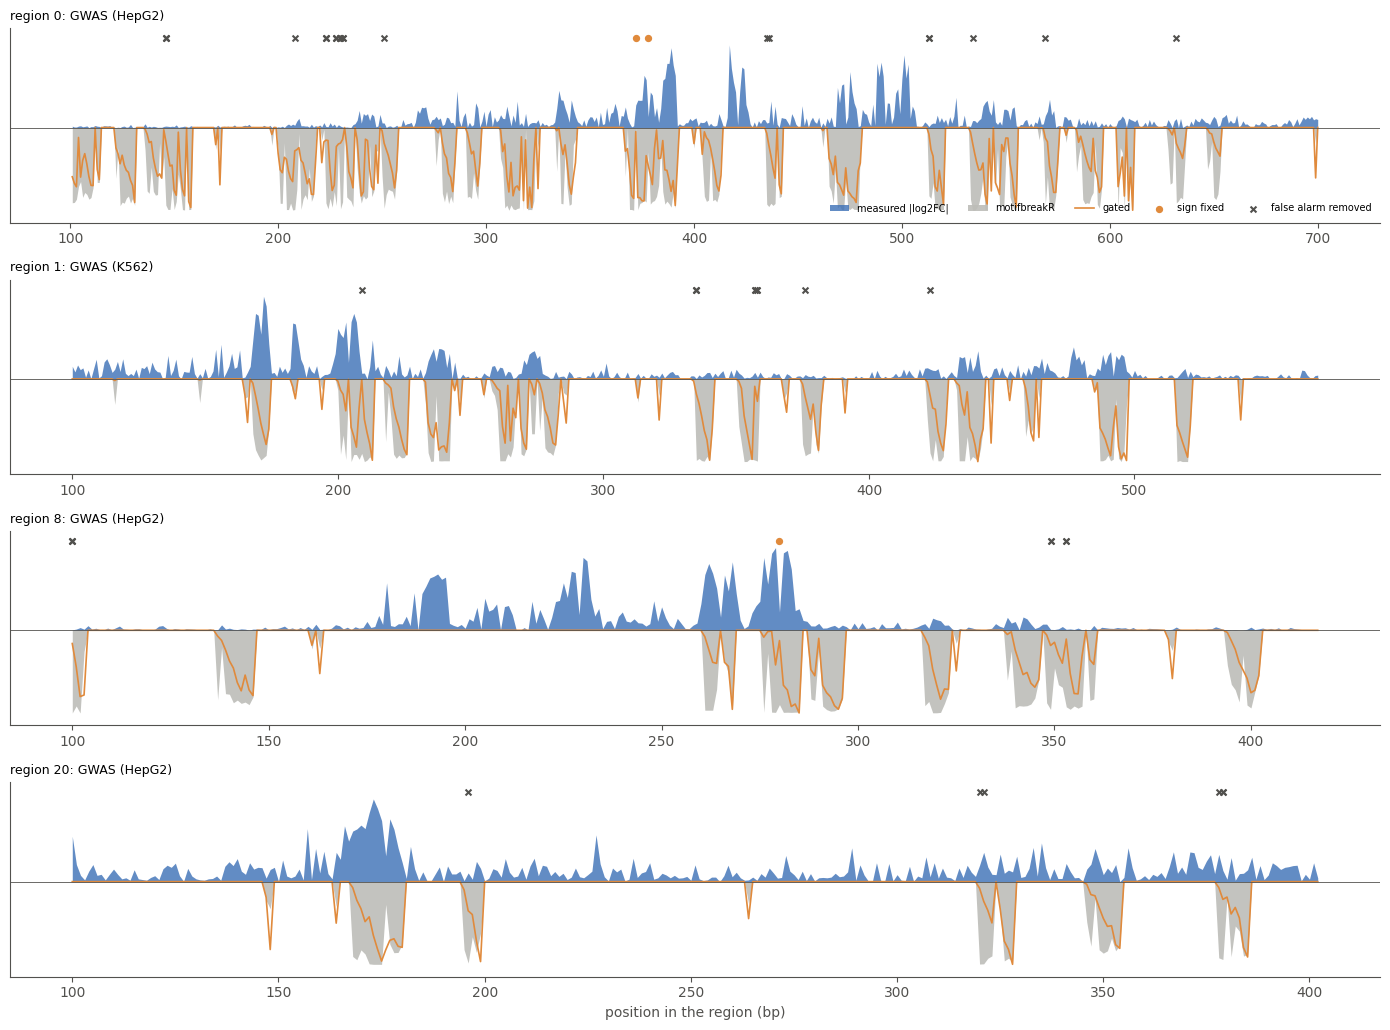

In [8]:
fig, axes = plt.subplots(len(KT), 1, figsize=(14, 2.6 * len(KT)), squeeze=False)
for a, (r, (R, t)) in zip(axes[:, 0], KT.items()):
    snv = R["snv"]
    pos = np.arange(snv["local"].min(), snv["local"].max() + 1)
    def per_base(local, v):
        s = pd.Series(v, index=local).groupby(level=0).mean().reindex(pos).fillna(0).values
        return s / (np.abs(s).max() or 1)
    meas = per_base(snv["local"].values, snv["log2FC"].values)
    mb = per_base(t["local"].values, t["pred mbR"].values)
    gt = per_base(t["local"].values, t["pred gate"].values)
    a.fill_between(pos, 0, np.abs(meas), color="#3b6fb6", alpha=0.8, lw=0, label="measured |log2FC|")
    a.fill_between(pos, 0, -np.abs(mb), color="#bdbdb8", alpha=0.9, lw=0, label="motifbreakR")
    a.plot(pos, -np.abs(gt), color="#e08a3c", lw=1.2, label="gated")
    for typ, mk, col in (("sign fixed", "o", "#e08a3c"), ("false alarm removed", "x", INK)):
        lp = t.loc[t[typ], "local"].values
        a.scatter(lp, np.full(len(lp), 1.08), marker=mk, s=18, color=col, label=typ)
    a.axhline(0, c=INK, lw=0.6)
    a.set_ylim(-1.15, 1.2); a.set_yticks([])
    a.set_title(f"region {r}: {DESC.at[r, 'description']} ({INFO[r]['cell']})", fontsize=9, loc="left")
axes[0, 0].legend(fontsize=7, ncol=5, loc="lower right", frameon=False)
axes[-1, 0].set_xlabel("position in the region (bp)")
plt.tight_layout(); plt.savefig(f"{OUT}/kircher_tracks.png", dpi=150, bbox_inches="tight"); plt.show()

## End

Outputs in `highlight_cases/`: `malinois_cases.csv`, `malinois_cases_HepG2.png`, `kircher_cases.csv`, `kircher_tracks.png`.